# Station feature coverage

This analysis uses the 2013-2014 GRINS AQCLIM file. A feature counts as measured at a station when at least one daily record for that station contains a non-missing value.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

DATA_DIR = Path.cwd() / "data"
ORIGIN_DIR = DATA_DIR / "processed"
DATA_FILE = ORIGIN_DIR / "raw.csv"
STATION_COL = "AirQualityStation"
DATE_COL = "time"
CHUNK_SIZE = 50_000

## Number of measured features per station

Read the file in chunks to avoid loading the full daily dataset into memory. For each station, count each feature once if it has at least one non-missing daily value.

In [2]:
if not DATA_FILE.is_file():
    raise FileNotFoundError(f"Measurement file not found: {DATA_FILE}")

columns = pd.read_csv(DATA_FILE, nrows=0).columns.tolist()
required_columns = {STATION_COL, DATE_COL}
missing_columns = required_columns.difference(columns)
if missing_columns:
    raise ValueError(f"Missing required columns in {DATA_FILE.name}: {sorted(missing_columns)}")

feature_cols = [col for col in columns if col not in required_columns]
feature_presence = pd.DataFrame(
    False,
    index=pd.Index([], name=STATION_COL, dtype="object"),
    columns=feature_cols,
    dtype=bool,
)

for chunk in pd.read_csv(
    DATA_FILE,
    usecols=[STATION_COL, *feature_cols],
    chunksize=CHUNK_SIZE,
):
    chunk_presence = chunk[feature_cols].notna().groupby(chunk[STATION_COL]).any()
    all_stations = feature_presence.index.union(chunk_presence.index, sort=False)
    feature_presence = feature_presence.reindex(all_stations, fill_value=False)
    chunk_presence = chunk_presence.reindex(
        index=all_stations,
        columns=feature_cols,
        fill_value=False,
    )
    feature_presence |= chunk_presence

features_per_station = (
    feature_presence.sum(axis=1)
    .rename("number_of_features")
    .sort_values(ascending=False)
)
station_counts_by_feature = (
    feature_presence.sum(axis=0)
    .rename("number_of_stations")
    .sort_values(ascending=False)
)

print(
    f"Processed {len(feature_presence):,} stations and {len(feature_cols)} features "
    f"from {DATA_FILE.name}."
)
features_per_station.to_frame()

Processed 744 stations and 58 features from raw.csv.


,number_of_features
AirQualityStation,
STA.IT1871A,52
STA.IT0663A,52
STA.IT1993A,52
STA.IT2009A,52
STA.IT2010A,52
...,...
STA.IT1852A,16
STA.IT0737A,16
STA.IT0853A,16


## Stations with measurements for each feature

Dropping unassigned features: ['Unnamed: 0']


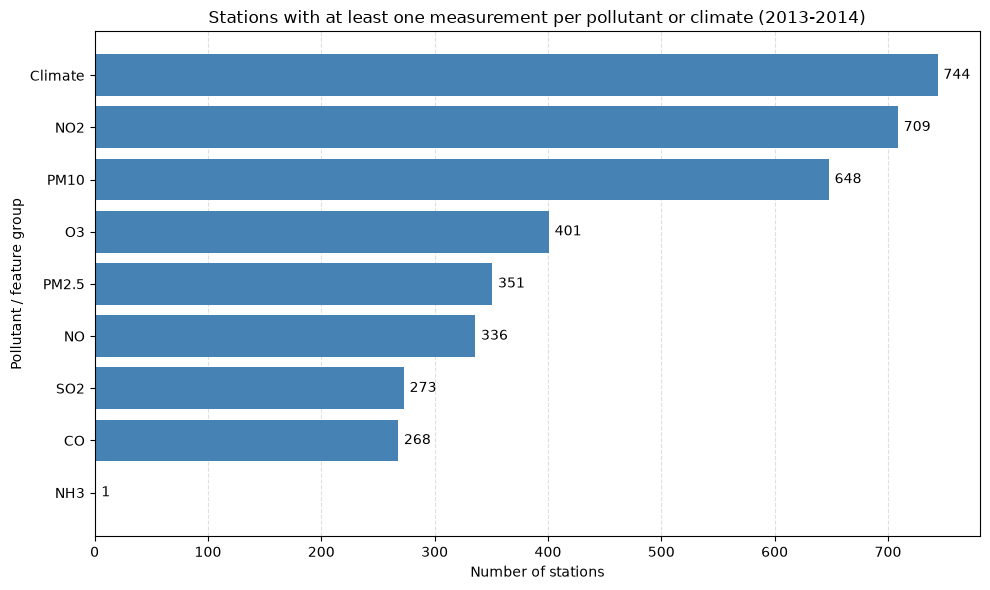

In [3]:
pollutants = ["NO2", "PM10", "O3", "PM2.5", "CO", "NO", "SO2", "NH3"]
feature_groups = {
    pollutant: [col for col in feature_cols if col.endswith(f"_{pollutant}")]
    for pollutant in pollutants
}
feature_groups["Climate"] = [col for col in feature_cols if col.startswith("CL_")]

assigned_features = {
    col for group in feature_groups.values() for col in group
}
unassigned_features = [col for col in feature_cols if col not in assigned_features]
if unassigned_features:
    print(f"Dropping unassigned features: {unassigned_features}")
    feature_cols = [col for col in feature_cols if col in assigned_features]
    feature_presence = feature_presence.drop(columns=unassigned_features)
    features_per_station = (
        feature_presence.sum(axis=1)
        .rename("number_of_features")
        .sort_values(ascending=False)
    )
    station_counts_by_feature = (
        feature_presence.sum(axis=0)
        .rename("number_of_stations")
        .sort_values(ascending=False)
    )

stations_by_group = pd.DataFrame(
    {
        group: feature_presence[cols].any(axis=1)
        for group, cols in feature_groups.items()
    },
    index=feature_presence.index,
)
station_counts_by_group = stations_by_group.sum().sort_values()

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(station_counts_by_group.index, station_counts_by_group.values, color="steelblue")
ax.bar_label(bars, fmt="%d", padding=4)
ax.set_title("Stations with at least one measurement per pollutant or climate (2013-2014)")
ax.set_xlabel("Number of stations")
ax.set_ylabel("Pollutant / feature group")
ax.grid(axis="x", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

## Missing pollutant values over time

For each aggregated file, plot the proportion of missing station-period pollutant means. Each pollutant's denominator includes only stations with at least one recorded value for that pollutant in that file; station-periods with no available value are counted as missing. Climate fields and NH3 are excluded.

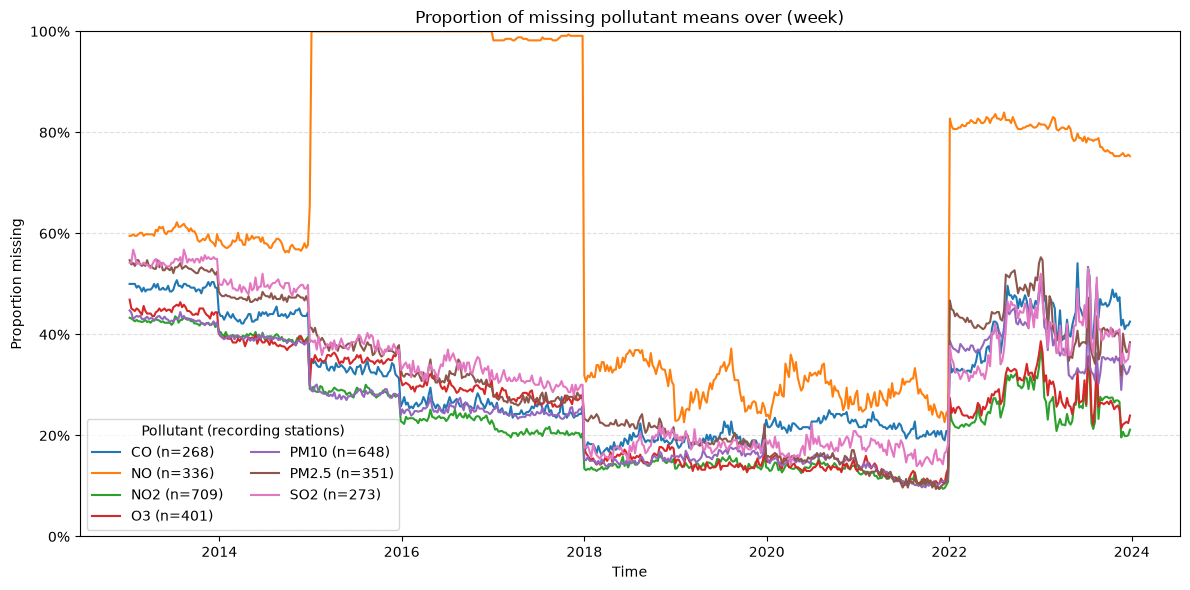

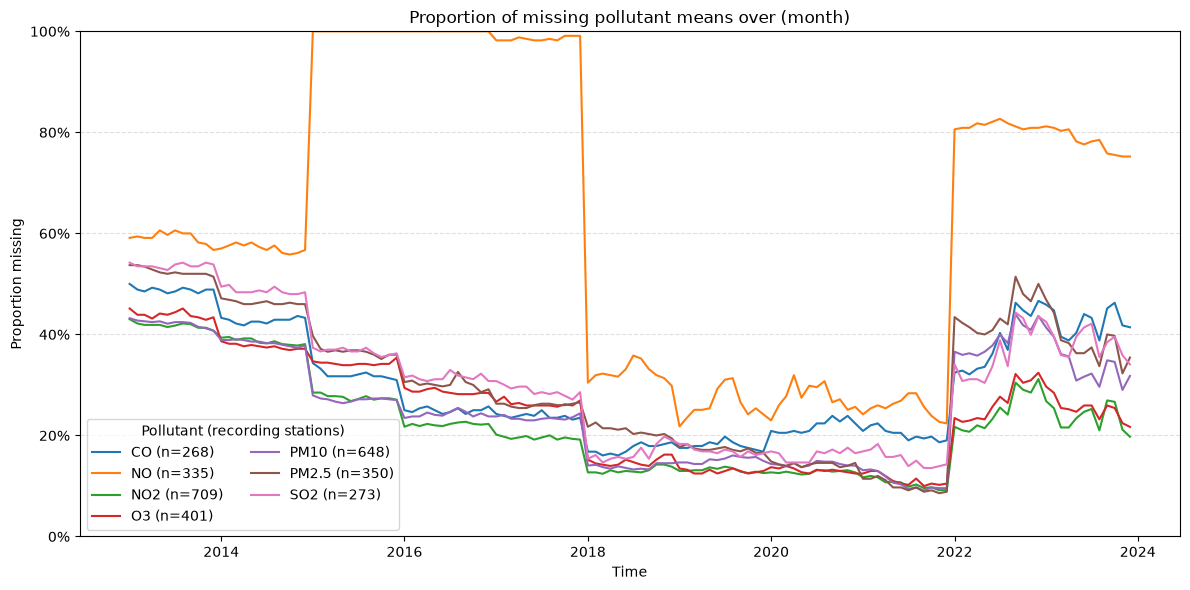

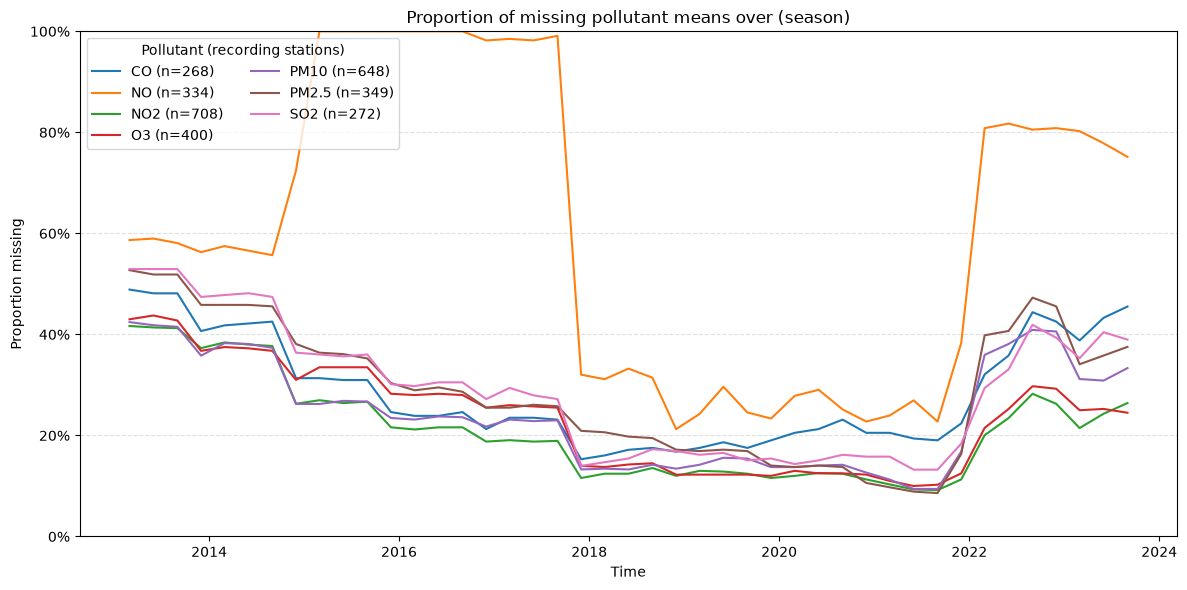

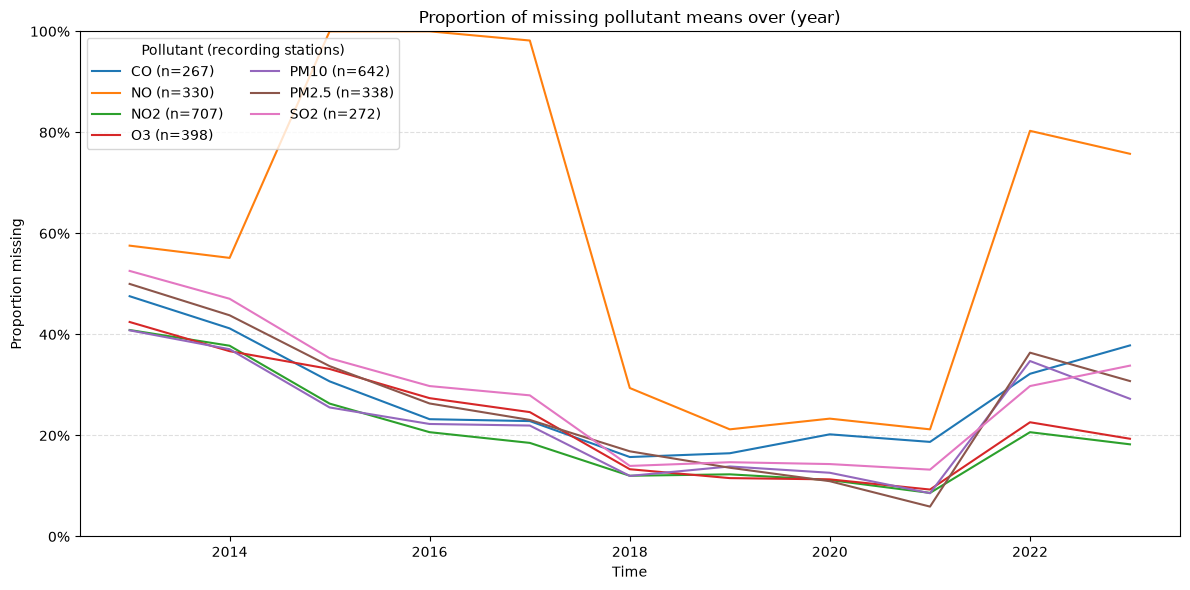

In [5]:
from matplotlib.ticker import PercentFormatter

AGGREGATED_FILES = {
    "week": ORIGIN_DIR / "aggregated_week.csv",
    "month": ORIGIN_DIR / "aggregated_month.csv",
    "season": ORIGIN_DIR / "aggregated_season.csv",
    "year": ORIGIN_DIR / "aggregated_year.csv",
}
POLLUTANT_MEAN_COLUMNS = {
    "CO": "CO_mean",
    "NO": "NO_mean",
    "NO2": "NO2_mean",
    "O3": "O3_mean",
    "PM10": "PM10_mean",
    "PM2.5": "PM25_mean",
    "SO2": "SO2_mean",
}
SEASON_START_MONTH = {
    "Spring": 3,
    "Summer": 6,
    "Autumn": 9,
    "Fall": 9,
    "Winter": 12,
}

for aggregation, aggregated_file in AGGREGATED_FILES.items():
    if not aggregated_file.is_file():
        raise FileNotFoundError(f"Aggregated file not found: {aggregated_file}")

    columns = pd.read_csv(aggregated_file, nrows=0).columns
    pollutant_columns = {
        pollutant: column
        for pollutant, column in POLLUTANT_MEAN_COLUMNS.items()
        if column in columns
    }
    time_columns = {
        "week": ["week"],
        "month": ["year", "month"],
        "season": ["year", "season"],
        "year": ["year"],
    }[aggregation]
    required_columns = [STATION_COL, *time_columns, *pollutant_columns.values()]
    data = pd.read_csv(aggregated_file, usecols=required_columns)

    if aggregation == "month":
        data["_period"] = pd.to_datetime(
            {"year": data["year"], "month": data["month"], "day": 1}
        )
    elif aggregation == "season":
        season_month = data["season"].map(SEASON_START_MONTH)
        if season_month.isna().any():
            unknown_seasons = sorted(data.loc[season_month.isna(), "season"].unique())
            raise ValueError(f"Unknown season labels in {aggregated_file.name}: {unknown_seasons}")
        data["_period"] = pd.to_datetime(
            {"year": data["year"], "month": season_month, "day": 1}
        )
    elif aggregation == "week":
        data["_period"] = pd.to_datetime(data["week"])
    else:
        data["_period"] = pd.to_datetime(data["year"].astype(str) + "-01-01")

    periods = pd.Index(data["_period"].dropna().unique()).sort_values()
    fig, ax = plt.subplots(figsize=(12, 6))
    plotted_pollutants = 0
    for pollutant, column in pollutant_columns.items():
        recorded = data.loc[data[column].notna(), [STATION_COL, "_period"]]
        recording_stations = recorded[STATION_COL].nunique()
        if recording_stations == 0:
            continue

        recorded_by_period = (
            recorded.groupby("_period")[STATION_COL]
            .nunique()
            .reindex(periods, fill_value=0)
        )
        missing_proportion = 1 - recorded_by_period / recording_stations
        ax.plot(
            periods,
            missing_proportion,
            label=f"{pollutant} (n={recording_stations})",
        )
        plotted_pollutants += 1

    ax.set_title(f"Proportion of missing pollutant means over ({aggregation})")
    ax.set_xlabel("Time")
    ax.set_ylabel("Proportion missing")
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.set_ylim(0, 1)
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    ax.set_axisbelow(True)
    if plotted_pollutants:
        ax.legend(title="Pollutant (recording stations)", ncol=2)
    fig.tight_layout()
    plt.show()